# Customer Cohort & Churn Analytics: statistical analysis

**Task 3 | Data Analytics & Power BI Internship**

This notebook backs up the Power BI dashboard with statistical tests. The dashboard shows *what* the churn patterns are. The tests here check whether those patterns could be down to chance, and which factors still matter when the others are held constant.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns).
**Folder layout expected:** `data/telco_customer_churn.csv` next to this `python/` folder.

**What this notebook does**
1. Loads the data and runs the same checks as the Power Query step (duplicates, blank `TotalCharges`)
2. Builds the tenure cohorts and monthly charge segments used in the dashboard
3. Calculates the baseline churn rate and churn by group
4. Runs chi-square tests with Cramér's V
5. Tests the high-risk example from the task: fiber optic customers with and without tech support
6. Compares tenure and monthly charges for churned and retained customers (Mann-Whitney U)
7. Builds the tenure-based cohort retention matrix
8. Fits a logistic regression to see what still matters after adjusting for other factors

**Libraries needed:** `pip install pandas numpy scipy statsmodels matplotlib`

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu
import statsmodels.formula.api as smf

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Colours that match the dashboard and report
NAVY, STEEL, LIGHT, GOLD, RED = "#22405F", "#4A6A8A", "#8FA9C7", "#C9A96E", "#B4636B"

## 1. Load and check the data

In [2]:
# Look for the CSV in the usual places, so the notebook runs from any of them
candidates = [
    "../data/telco_customer_churn.csv",
    "data/telco_customer_churn.csv",
    "telco_customer_churn.csv",
]
data_path = next((p for p in candidates if Path(p).exists()), None)
if data_path is None:
    raise FileNotFoundError("telco_customer_churn.csv not found. Put it in the data/ folder.")

df = pd.read_csv(data_path)
print("Rows, columns:", df.shape)
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Rows, columns: (7043, 21)
Duplicate customer IDs: 0
Fully duplicated rows: 0


In [3]:
# TotalCharges is stored as text because 11 entries are blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df["TotalCharges"].isna()

print("Blank TotalCharges rows:", blank.sum())
print("Their tenure values:", df.loc[blank, "tenure"].unique())
print("Their churn values: ", df.loc[blank, "Churn"].unique())

# These customers have 0 months of tenure and have not been billed yet,
# so their total is genuinely 0. Keeping them avoids distorting the churn rate.
df.loc[blank, "TotalCharges"] = 0
print("Blank TotalCharges after fix:", df["TotalCharges"].isna().sum())

Blank TotalCharges rows: 11
Their tenure values: [0]
Their churn values:  <StringArray>
['No']
Length: 1, dtype: str
Blank TotalCharges after fix: 0


## 2. Build the dashboard groupings

These match the columns created in Power Query: tenure cohorts (0-12, 13-24, 25-48, 49-72 months) and monthly charge segments (Low under \$35, Medium \$35 to under \$70, High \$70 and above).

In [4]:
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

df["Tenure Cohort"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
)
df["Charge Segment"] = pd.cut(
    df["MonthlyCharges"], bins=[0, 35, 70, np.inf], right=False,
    labels=["Low (<$35)", "Medium ($35-$70)", "High ($70+)"],
)
df[["tenure", "Tenure Cohort", "MonthlyCharges", "Charge Segment", "Churn"]].head()

,tenure,Tenure Cohort,MonthlyCharges,Charge Segment,Churn
0,1,0-12 months,29.85,Low (<$35),No
1,34,25-48 months,56.95,Medium ($35-$70),No
2,2,0-12 months,53.85,Medium ($35-$70),Yes
3,45,25-48 months,42.30,Medium ($35-$70),No
4,2,0-12 months,70.70,High ($70+),Yes


## 3. Baseline churn

In [5]:
total = len(df)
churned = int(df["churn_flag"].sum())
revenue_at_risk = df.loc[df["churn_flag"] == 1, "MonthlyCharges"].sum()

print(f"Total customers:         {total:,}")
print(f"Churned customers:       {churned:,}")
print(f"Retained customers:      {total - churned:,}")
print(f"Churn rate:              {churned / total:.2%}")
print(f"Retention rate:          {1 - churned / total:.2%}")
print(f"Average monthly charges: ${df['MonthlyCharges'].mean():.2f}")
print(f"Monthly revenue at risk: ${revenue_at_risk:,.0f}")
print(f"Average tenure:          {df['tenure'].mean():.2f} months")

Total customers:         7,043
Churned customers:       1,869
Retained customers:      5,174
Churn rate:              26.54%
Retention rate:          73.46%
Average monthly charges: $64.76
Monthly revenue at risk: $139,131
Average tenure:          32.37 months


## 4. Churn rate by group

In [6]:
def churn_table(column):
    g = df.groupby(column, observed=True).agg(
        customers=("churn_flag", "size"),
        churned=("churn_flag", "sum"),
    )
    g["churn_rate_%"] = g["churned"] / g["customers"] * 100
    g["share_of_all_churners_%"] = g["churned"] / churned * 100
    return g

for col in ["Contract", "Tenure Cohort", "PaymentMethod", "Charge Segment", "InternetService", "TechSupport"]:
    print(f"\n--- {col} ---")
    display(churn_table(col))


--- Contract ---


,customers,churned,churn_rate_%,share_of_all_churners_%
Contract,,,,
Month-to-month,3875,1655,42.71,88.55
One year,1473,166,11.27,8.88
Two year,1695,48,2.83,2.57



--- Tenure Cohort ---


,customers,churned,churn_rate_%,share_of_all_churners_%
Tenure Cohort,,,,
0-12 months,2186,1037,47.44,55.48
13-24 months,1024,294,28.71,15.73
25-48 months,1594,325,20.39,17.39
49-72 months,2239,213,9.51,11.40



--- PaymentMethod ---


,customers,churned,churn_rate_%,share_of_all_churners_%
PaymentMethod,,,,
Bank transfer (automatic),1544,258,16.71,13.80
Credit card (automatic),1522,232,15.24,12.41
Electronic check,2365,1071,45.29,57.30
Mailed check,1612,308,19.11,16.48


... (2 outputs left out)


--- InternetService ---


,customers,churned,churn_rate_%,share_of_all_churners_%
InternetService,,,,
DSL,2421,459,18.96,24.56
Fiber optic,3096,1297,41.89,69.40
No,1526,113,7.40,6.05



--- TechSupport ---


,customers,churned,churn_rate_%,share_of_all_churners_%
TechSupport,,,,
No,3473,1446,41.64,77.37
No internet service,1526,113,7.40,6.05
Yes,2044,310,15.17,16.59


## 5. Chi-square tests of independence

For each category we ask: is churn linked to this factor, or could the pattern be chance? The **p-value** answers that. **Cramér's V** says how strong the link is, from 0 (none) to 1 (perfect).

In [7]:
factors = {
    "Contract": "Contract",
    "Tenure cohort": "Tenure Cohort",
    "Tech support": "TechSupport",
    "Internet service": "InternetService",
    "Payment method": "PaymentMethod",
    "Monthly charge segment": "Charge Segment",
}

rows = []
for label, col in factors.items():
    table = pd.crosstab(df[col], df["churn_flag"])
    chi2, p, dof, expected = chi2_contingency(table)
    v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))
    rows.append({
        "Factor": label, "Chi-square": chi2, "df": dof, "Cramér's V": v,
        "p-value": "< 0.001" if p < 0.001 else f"{p:.3f}",
        "Smallest expected count": expected.min(),
    })

chi_df = pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)
chi_df.style.format({"Chi-square": "{:,.1f}", "Cramér's V": "{:.3f}", "Smallest expected count": "{:,.0f}"})

,Factor,Chi-square,df,Cramér's V,p-value,Smallest expected count
0,Contract,"1,184.6",2,0.410,< 0.001,391
1,Tenure cohort,856.1,3,0.349,< 0.001,272
2,Tech support,828.2,2,0.343,< 0.001,405
3,Internet service,732.3,2,0.322,< 0.001,405
4,Payment method,648.1,3,0.303,< 0.001,404
5,Monthly charge segment,372.8,2,0.230,< 0.001,457


Smallest expected count across all tests: 272


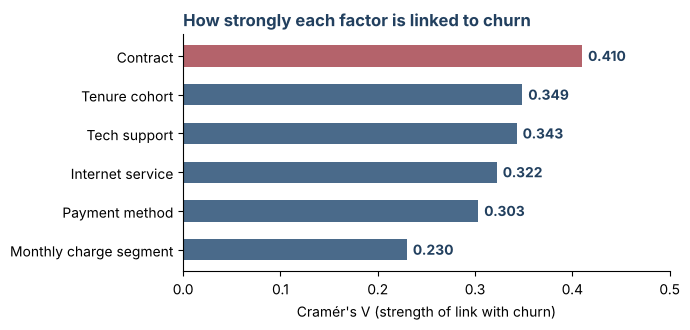

In [8]:
# The chi-square test needs every expected count to be at least 5
print("Smallest expected count across all tests:", round(chi_df["Smallest expected count"].min()))

plot_df = chi_df.sort_values("Cramér's V")
colors = [RED if v == plot_df["Cramér's V"].max() else STEEL for v in plot_df["Cramér's V"]]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(plot_df["Factor"], plot_df["Cramér's V"], color=colors, height=0.55)
for i, v in enumerate(plot_df["Cramér's V"]):
    ax.text(v + 0.006, i, f"{v:.3f}", va="center", color=NAVY, fontweight="bold")
ax.set_xlim(0, 0.5)
ax.set_xlabel("Cramér's V (strength of link with churn)")
ax.set_title("How strongly each factor is linked to churn", loc="left", color=NAVY, fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## 6. The task's high-risk example: fiber optic with and without tech support

In [9]:
fiber = df[df["InternetService"] == "Fiber optic"]
ct = pd.crosstab(fiber["TechSupport"], fiber["Churn"])
ct["churn_rate_%"] = ct["Yes"] / (ct["Yes"] + ct["No"]) * 100
display(ct)

chi2, p, dof, _ = chi2_contingency(pd.crosstab(fiber["TechSupport"], fiber["churn_flag"]))
print(f"Chi-square = {chi2:.1f}, df = {dof}, p {'< 0.001' if p < 0.001 else '= ' + format(p, '.3f')}")

# How concentrated is churn in this one group?
seg = df[(df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No")]
print(f"\nFiber optic, no tech support: {len(seg):,} customers ({len(seg)/total:.1%} of all customers)")
print(f"  Churned: {int(seg['churn_flag'].sum()):,} ({seg['churn_flag'].mean():.2%} churn rate)")
print(f"  Share of all churners: {seg['churn_flag'].sum()/churned:.1%}")
print(f"  Monthly revenue at risk: ${seg.loc[seg['churn_flag']==1,'MonthlyCharges'].sum():,.0f}")

seg_m = seg[seg["Contract"] == "Month-to-month"]
seg_e = seg_m[seg_m["PaymentMethod"] == "Electronic check"]
print(f"  ...and month-to-month: {seg_m['churn_flag'].mean():.2%} ({len(seg_m):,} customers)")
print(f"  ...and electronic check: {seg_e['churn_flag'].mean():.2%} ({len(seg_e):,} customers)")

Churn,No,Yes,churn_rate_%
TechSupport,,,
No,1129,1101,49.37
Yes,670,196,22.63


Chi-square = 182.1, df = 1, p < 0.001



Fiber optic, no tech support: 2,230 customers (31.7% of all customers)
  Churned: 1,101 (49.37% churn rate)
  Share of all churners: 58.9%
  Monthly revenue at risk: $94,901
  ...and month-to-month: 57.52% (1,796 customers)
  ...and electronic check: 62.92% (1,138 customers)


## 7. Tenure and monthly charges: churned vs retained (Mann-Whitney U)

Tenure is not normally distributed, so a Mann-Whitney U test is safer than a t-test.

In [10]:
for col, label in [("tenure", "Tenure (months)"), ("MonthlyCharges", "Monthly charges ($)")]:
    churned_vals = df.loc[df["churn_flag"] == 1, col]
    retained_vals = df.loc[df["churn_flag"] == 0, col]
    stat, p = mannwhitneyu(churned_vals, retained_vals)
    print(f"{label}: median churned = {churned_vals.median():.2f}, "
          f"median retained = {retained_vals.median():.2f}, "
          f"p {'< 0.001' if p < 0.001 else '= ' + format(p, '.3f')}")

Tenure (months): median churned = 10.00, median retained = 38.00, p < 0.001
Monthly charges ($): median churned = 79.65, median retained = 64.43, p < 0.001


## 8. Tenure-based cohort retention matrix

The data is a snapshot with no signup dates, so this is **not** a month-by-month cohort curve. It compares groups of customers by how long they have been with the company. Customers in the 49-72 month band are people who stayed, so the matrix compares different customers and does not show how one group changes over time.

In [11]:
retention = df.pivot_table(
    index="Tenure Cohort", columns="Contract", values="churn_flag",
    aggfunc=lambda s: (1 - s.mean()) * 100, observed=True,
)
counts = df.pivot_table(
    index="Tenure Cohort", columns="Contract", values="churn_flag",
    aggfunc="size", observed=True,
)
retention["All contracts"] = df.groupby("Tenure Cohort", observed=True)["churn_flag"].apply(lambda s: (1 - s.mean()) * 100)
counts["All contracts"] = df.groupby("Tenure Cohort", observed=True).size()
display(retention.round(2))

Contract,Month-to-month,One year,Two year,All contracts
Tenure Cohort,,,,
0-12 months,48.65,89.52,100.00,52.56
13-24 months,62.28,91.88,100.00,71.29
25-48 months,67.08,89.38,97.81,79.61
49-72 months,73.98,87.07,96.67,90.49


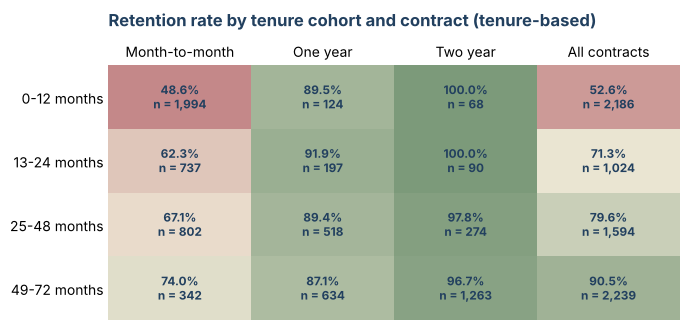

In [12]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("ret", [RED, "#EFE9D6", "#7C9A7A"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.imshow(retention.values, cmap=cmap, vmin=40, vmax=100, aspect="auto")
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        ax.text(j, i, f"{retention.values[i, j]:.1f}%\nn = {counts.values[i, j]:,}",
                ha="center", va="center", color=NAVY, fontsize=8.5, fontweight="bold")
ax.set_xticks(range(retention.shape[1])); ax.set_xticklabels(retention.columns)
ax.set_yticks(range(retention.shape[0])); ax.set_yticklabels(retention.index)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Retention rate by tenure cohort and contract (tenure-based)", loc="left", color=NAVY, fontweight="bold", pad=28)
plt.tight_layout()
plt.show()

## 9. Logistic regression: what still matters when other factors are held constant?

A simple chart can mislead when factors overlap. For example, fiber optic customers also tend to pay more, so price and service type are tangled together. The regression estimates each factor's link with churn while holding the others constant.

It is run on customers **with internet service** (5,517), because "No internet service" in the tech support column overlaps exactly with having no internet plan.

An **odds ratio** above 1 means higher odds of churning than the reference group. Below 1 means lower odds.

In [13]:
net = df[df["InternetService"] != "No"].copy()

formula = (
    'churn_flag ~ C(Contract, Treatment("Month-to-month"))'
    ' + C(InternetService, Treatment("DSL"))'
    ' + C(TechSupport, Treatment("Yes"))'
    ' + C(PaymentMethod, Treatment("Credit card (automatic)"))'
    " + tenure + MonthlyCharges"
)
model = smf.logit(formula, data=net).fit(disp=False)
print(f"Customers in the model: {len(net):,}")
print(f"Pseudo R-squared: {model.prsquared:.3f}")

readable = {
    "[T.One year]": "One-year vs month-to-month",
    "[T.Two year]": "Two-year vs month-to-month",
    "[T.Fiber optic]": "Fiber optic vs DSL",
    "[T.No]": "No tech support vs tech support",
    "[T.Electronic check]": "Electronic check vs credit card (auto)",
    "[T.Bank transfer (automatic)]": "Bank transfer (auto) vs credit card (auto)",
    "[T.Mailed check]": "Mailed check vs credit card (auto)",
    "tenure": "Each extra month of tenure",
    "MonthlyCharges": "Each extra $1 of monthly charge",
}
ci = np.exp(model.conf_int())
rows = []
for name in model.params.index[1:]:
    label = next(v for k, v in readable.items() if k in name)
    rows.append({
        "Factor": label,
        "Odds ratio": np.exp(model.params[name]),
        "CI lower": ci.loc[name, 0], "CI upper": ci.loc[name, 1],
        "p-value": model.pvalues[name],
        "Significant (p < 0.05)": "Yes" if model.pvalues[name] < 0.05 else "No",
    })
odds = pd.DataFrame(rows)
odds.style.format({"Odds ratio": "{:.2f}", "CI lower": "{:.2f}", "CI upper": "{:.2f}", "p-value": "{:.4f}"})

Customers in the model: 5,517
Pseudo R-squared: 0.226


,Factor,Odds ratio,CI lower,CI upper,p-value,Significant (p < 0.05)
0,One-year vs month-to-month,0.52,0.42,0.65,0.0000,Yes
1,Two-year vs month-to-month,0.26,0.18,0.37,0.0000,Yes
2,Fiber optic vs DSL,2.21,1.70,2.88,0.0000,Yes
3,No tech support vs tech support,1.54,1.30,1.82,0.0000,Yes
4,Bank transfer (auto) vs credit card (auto),1.00,0.80,1.26,0.9747,No
5,Electronic check vs credit card (auto),1.60,1.32,1.94,0.0000,Yes
6,Mailed check vs credit card (auto),0.94,0.74,1.19,0.6007,No
7,Each extra month of tenure,0.97,0.97,0.97,0.0000,Yes
8,Each extra $1 of monthly charge,1.01,1.00,1.01,0.0281,Yes


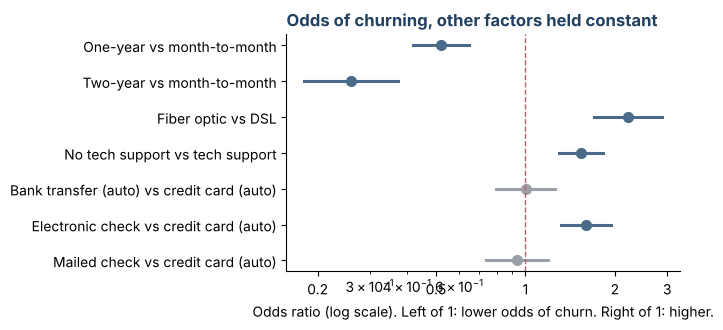

In [14]:
plot = odds[~odds["Factor"].str.startswith("Each")].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (_, r) in enumerate(plot.iterrows()):
    color = STEEL if r["Significant (p < 0.05)"] == "Yes" else "#9AA0A8"
    ax.plot([r["CI lower"], r["CI upper"]], [i, i], color=color, lw=2.2)
    ax.plot(r["Odds ratio"], i, "o", color=color, ms=7)
ax.axvline(1, color=RED, ls="--", lw=1)
ax.set_xscale("log"); ax.set_xticks([0.2, 0.5, 1, 2, 3]); ax.set_xticklabels(["0.2", "0.5", "1", "2", "3"])
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot["Factor"])
ax.set_xlabel("Odds ratio (log scale). Left of 1: lower odds of churn. Right of 1: higher.")
ax.set_title("Odds of churning, other factors held constant", loc="left", color=NAVY, fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## 10. How to read these results

- **Every factor tested has a statistically significant link with churn** (all p-values below 0.001). Contract type has the strongest link, and monthly charge segment the weakest.
- **After adjusting for other factors**, contract type, fiber optic service, missing tech support and electronic check stay linked to churn. Bank transfer and mailed check are no different from credit card, and monthly charges barely matter on their own.
- **This is association, not cause.** The dataset is observational and has nothing on service quality, outages, customer satisfaction or competitor offers. The findings are strong leads to test with small pilots, not proof that changing one factor will change churn.
- **The cohort matrix is tenure-based.** A true cohort retention curve would need signup dates and a monthly record of whether each customer was still active.